# Chronos-2 | Zero-Shot Forecasting of Multivariate Sensor Data

**A reproducible technical case study on time-series foundation models**

Estela Sánchez-Carballo · November 2026

### Overview

This study investigates the zero-shot forecasting capabilities of Chronos-2, a pretrained time-series foundation model, on multivariate sensor data from the ETTh1 dataset. The objective is to evaluate forecasting accuracy, investigate the contribution of cross-channel information, and assess prediction uncertainty under a controlled experimental protocol.

### Research questions

- **RQ1 — Forecasting performance:** How does Chronos-2 compare against classical forecasting baselines?
- **RQ2 — Multivariate information:** Does joint-channel inference improve forecasting accuracy compared with independent-channel inference?
- **RQ3 — Robustness and uncertainty:** How does model performance vary across channels and forecast origins, and how well do prediction intervals capture observed values?

### Methodological approach

The study compares persistence, seasonal naive, and two Chronos-2 inference configurations using identical forecasting horizons and evaluation periods. Experiments use 48 non-overlapping 24-hour forecast targets within the conventional ETTh1 test partition, with 168 hours of historical context. All evaluations are performed without task-specific training or fine-tuning. Results are analyzed using MAE, RMSE, empirical prediction interval coverage, and channel-level and temporal comparisons.


## 1 · Reproducible Environment

This notebook requires the Python packages listed in `requirements.txt`.

The installation cell below is optional:

- **New environment:** Run the installation cell to install the required dependencies.
- **Existing virtual environment:** Skip the cell if dependencies have already been installed using `pip install -r requirements.txt`.

The installation command assumes that `requirements.txt` is located in the current working directory.

Chronos-2 supports CPU and GPU inference. A GPU is recommended for larger evaluations but is not required to reproduce this experiment.

In [ ]:
%pip install -q -r requirements.txt

In [2]:
import json, platform, time
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from sklearn.metrics import mean_absolute_error, mean_squared_error
from chronos import Chronos2Pipeline

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_ID = "amazon/chronos-2"
DATA_URL = "https://huggingface.co/datasets/thuml/Time-Series-Library/resolve/main/ETT-small/ETTh1.csv"
OUT = Path("chronos2_results_final")
OUT.mkdir(exist_ok=True, parents=True)
plt.rcParams.update({"figure.dpi": 115, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

print({"device": DEVICE, "torch": torch.__version__,
       "chronos_forecasting": version("chronos-forecasting"), "python": platform.python_version()})

c:\Users\Estela Sánchez\OneDrive - Universidad Rey Juan Carlos\Escritorio\Trabajo\Time-Series Foundation Models\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'device': 'cpu', 'torch': '2.15.0+cpu', 'chronos_forecasting': '2.3.2', 'python': '3.11.9'}


## 2 · Dataset & Evaluation Protocol

### Dataset

The ETTh1 dataset contains seven hourly time-series channels collected from an electricity transformer system. The data are validated for missing values, temporal continuity, duplicate timestamps, and numerical consistency before evaluation.

### Evaluation design

The study follows a rolling-origin forecasting protocol using the conventional ETTh1 test partition defined in Time-Series-Library.

| Parameter | Configuration |
|---|---|
| Dataset | ETTh1 |
| Evaluation partition | Conventional test split |
| Forecast origins | 48 |
| Context length | 168 hours |
| Prediction horizon | 24 hours |
| Target overlap | None |
| Input channels | 7 |
| Model adaptation | None (zero-shot) |

Each forecast uses only observations available before its prediction origin. All methods are evaluated using identical historical windows and future targets.

### Performance assessment

Forecasting accuracy is evaluated separately for each channel using MAE RMSE.Global performance is reported using macro-averages across the seven channels. Since channels are evaluated in their original numerical scales, these aggregate metrics should be interpreted alongside the channel-level results. The evaluation also examines empirical prediction interval coverage and temporal variations in forecasting accuracy.

In [3]:
# Forecasting configuration
CONTEXT = 168 # Historical observations (hours)
HORIZON = 24 # Forecast horizon (hours)
N_ORIGINS = 48 # Non-overlapping forecast origins
# Evaluation uses the conventional ETTh1 test partition

frame = pd.read_csv(DATA_URL)
frame["date"] = pd.to_datetime(frame["date"])
channels = [c for c in frame.columns if c != "date"]
assert len(channels) == 7, f"Unexpected channels: {channels}"
assert not frame[channels].isna().any().any()
assert frame["date"].is_monotonic_increasing
assert not frame["date"].duplicated().any()
assert (frame["date"].diff().iloc[1:] == pd.Timedelta(hours=1)).all()
values = frame[channels].to_numpy(dtype=np.float32)
assert np.isfinite(values).all()

# Conventional ETTh1 test boundaries (Time-Series-Library)
# Source-row indices, with an exclusive upper bound.
test_start = (12 + 4) * 30 * 24
test_end = (12 + 8) * 30 * 24

assert test_end <= len(values)
assert test_end - test_start >= N_ORIGINS * HORIZON
origins = np.arange(test_end - N_ORIGINS * HORIZON, test_end, HORIZON, dtype=int)
assert len(origins) == N_ORIGINS
assert origins[0] >= max(CONTEXT, test_start)
assert origins[-1] + HORIZON == test_end
assert np.all(np.diff(origins) == HORIZON)

contexts = np.stack([values[o-CONTEXT:o].T for o in origins])
truth = np.stack([values[o:o+HORIZON].T for o in origins])
assert contexts.shape == (N_ORIGINS, len(channels), CONTEXT)
assert truth.shape == (N_ORIGINS, len(channels), HORIZON)
assert np.array_equal(contexts[:, :, -1], values[origins-1])
assert np.array_equal(truth[:, :, 0], values[origins])
assert not any(set(range(o, o+HORIZON)) & set(range(p,p+HORIZON))
               for o,p in zip(origins[:-1], origins[1:]))

print("Evaluation partition: ETTh1 conventional test split")
print("Dataset rows:", len(frame), "Channels:", channels)
print("First target:", frame.date.iloc[origins[0]])
print("Last target:", frame.date.iloc[origins[-1] + HORIZON - 1])
print("Context tensor:", contexts.shape, "Target tensor:", truth.shape)
print("\n")
display(frame.head(3))

Evaluation partition: ETTh1 conventional test split
Dataset rows: 17420 Channels: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
First target: 2018-01-04 00:00:00
Last target: 2018-02-20 23:00:00
Context tensor: (48, 7, 168) Target tensor: (48, 7, 24)




,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001


## 3 · Forecasting Methods

Four forecasting approaches are evaluated under identical experimental conditions.

### Classical baselines

- **Persistence:** Predicts the last observed value for all future timestamps.
- **Seasonal naive:** Repeats the observations from the preceding 24-hour cycle, capturing daily periodicity without model fitting.

### Time-Series Foundation Model: Chronos-2

Chronos-2 is a pretrained Transformer-based time-series foundation model. Its public pretrained weights are used directly, without task-specific fine-tuning. Two inference configurations are compared:

- **Joint-channel inference:** All seven channels are provided as a single multivariate input, allowing the model to exploit information across channels.
- **Independent-channel inference:** Each channel is supplied as a separate univariate input, restricting the forecast to its own historical observations.

Both configurations use identical model weights, context lengths, prediction horizons, and evaluation timestamps. The `cross_learning=False` setting disables information sharing between separate input tasks while preserving the possibility of cross-channel information exchange within a multivariate input. This comparison evaluates the effect of input configuration rather than differences between trained models. In addition to point forecasts, Chronos-2 produces predictive quantiles (P10, P50, and P90), enabling an exploratory assessment of uncertainty calibration.

In [4]:
def to_numpy(x):
    return x.detach().cpu().numpy() if isinstance(x, torch.Tensor) else np.asarray(x)

# Baselines: forecast arrays [origin, channel, horizon].
persistence = np.repeat(contexts[:, :, -1:], HORIZON, axis=2)
assert HORIZON <= CONTEXT
# For a 24-hour horizon, the last observed day is the next predicted day.
assert HORIZON == 24, "Update seasonal-naive indexing for other horizons."
seasonal_naive = contexts[:, :, -24:].copy()
assert persistence.shape == seasonal_naive.shape == truth.shape

load_start = time.perf_counter()
pipeline = Chronos2Pipeline.from_pretrained(MODEL_ID, device_map=DEVICE)
load_seconds = time.perf_counter() - load_start
print(f"Chronos-2 loaded on {DEVICE} in {load_seconds:.2f} s")

c:\Users\Estela Sánchez\OneDrive - Universidad Rey Juan Carlos\Escritorio\Trabajo\Time-Series Foundation Models\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Estela Sánchez\.cache\huggingface\hub\models--amazon--chronos-2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Estela Sánchez\O

Chronos-2 loaded on cpu in 15.67 s


In [5]:
QUANTILES = [0.1, 0.5, 0.9]

def run_chronos(inputs, chunk_size=8, batch_size=64):
    """Return median and P10/P50/P90; preserve caller input order."""
    point_list, quantile_list = [], []
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    start_time = time.perf_counter()
    with torch.inference_mode():
        for start in range(0, len(inputs), chunk_size):
            chunk = inputs[start:start + chunk_size]
            quantiles, point = pipeline.predict_quantiles(
                inputs=chunk, prediction_length=HORIZON,
                quantile_levels=QUANTILES, batch_size=batch_size,
                cross_learning=False
            )
            point_list.extend(to_numpy(x) for x in point)
            quantile_list.extend(to_numpy(x) for x in quantiles)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    return np.stack(point_list), np.stack(quantile_list), time.perf_counter() - start_time

joint_inputs = [contexts[i] for i in range(N_ORIGINS)]
independent_inputs = [contexts[i, j].copy()
                      for i in range(N_ORIGINS) for j in range(len(channels))]
assert joint_inputs[0].shape == (7, 168)
assert independent_inputs[0].shape == (168,)

# This invocation can be repeated on CPU/GPU, but raw timing is not a speed comparison.
forecast_joint, joint_q, joint_time = run_chronos(joint_inputs, chunk_size=8, batch_size=64)
forecast_ind_flat, indep_q_flat, independent_time = run_chronos(
    independent_inputs, chunk_size=56, batch_size=64
)
forecast_independent = forecast_ind_flat.reshape(N_ORIGINS, len(channels), HORIZON)
independent_q = indep_q_flat.reshape(N_ORIGINS, len(channels), HORIZON, len(QUANTILES))
assert forecast_joint.shape == forecast_independent.shape == truth.shape
assert joint_q.shape == independent_q.shape == (*truth.shape, len(QUANTILES))
assert np.isfinite(forecast_joint).all() and np.isfinite(forecast_independent).all()
assert np.isfinite(joint_q).all() and np.isfinite(independent_q).all()
print(f"Joint inference: {joint_time:.2f}s | Independent inference: {independent_time:.2f}s")
print("Forecasts:", forecast_joint.shape, "Quantiles:", joint_q.shape)

Joint inference: 6.58s | Independent inference: 6.34s
Forecasts: (48, 7, 24) Quantiles: (48, 7, 24, 3)


## 4 · Forecasting Performance

Forecasting performance is evaluated over 48 non-overlapping prediction horizons. MAE and RMSE are first computed for each channel across all forecast targets and then macro-averaged across channels. Macro RMSE therefore represents the mean of channel-level RMSE values rather than a single pooled RMSE. The comparison includes classical baselines and both Chronos-2 inference configurations. Channel-level metrics are reported to identify differences that may be obscured by aggregate performance.

In [6]:
METHODS = {
    "Persistence": persistence,
    "Seasonal naive": seasonal_naive,
    "Chronos-2 joint": forecast_joint,
    "Chronos-2 independent": forecast_independent,
}
METHOD_ORDER = list(METHODS)

def compute_channel_metrics(targets, predictions, column_names):
    records = []
    for name, pred in predictions.items():
        assert pred.shape == targets.shape
        for j, channel in enumerate(column_names):
            y = targets[:, j, :].ravel()
            yhat = pred[:, j, :].ravel()
            records.append({"method": name, "channel": channel,
                            "MAE": mean_absolute_error(y, yhat),
                            "RMSE": np.sqrt(mean_squared_error(y, yhat))})
    return pd.DataFrame(records)

def macro_average(channel_table):
    return (channel_table.groupby("method")[['MAE', 'RMSE']]
            .mean().reindex(METHOD_ORDER))

# Primary evaluation: all 48 forecast origins
channel_metrics = compute_channel_metrics(truth, METHODS, channels)
macro = macro_average(channel_metrics)

C_STYLE = [
    {"selector": "caption", "props": [("font-weight", "bold"), ("font-size", "15px"),
                                    ("text-align", "left"), ("padding-bottom", "9px")]},
    {"selector": "th", "props": [("background", "#eef2f7"), ("padding", "9px"),
                               ("text-align", "center")]},
    {"selector": "td", "props": [("padding", "9px"), ("text-align", "center"),
                               ("border-bottom", "1px solid #e8ecf2")]},
]

def shade_best(row):
    ranks = row.rank(method="min")
    palette = {1: "#daf3e5", 2: "#f8f3d7", 3: "#fde9e6", 4: "#fde0dd"}
    return [f"background-color: {palette.get(int(r), '#fff')}; "
            + ("font-weight: bold" if r == 1 else "") for r in ranks]

display(macro.style.format("{:.3f}")
    .set_caption(f"Forecasting performance — {N_ORIGINS} origins")
    .set_table_styles(C_STYLE))
print("\n")

for metric in ["MAE", "RMSE"]:
    pivot = (channel_metrics.pivot(index="channel", columns="method", values=metric)
             .reindex(index=channels, columns=METHOD_ORDER))
    display(pivot.style.format("{:.3f}").apply(shade_best, axis=1)
            .set_caption(f"48 origins · {metric} by channel (row-relative color ranking)")
            .set_table_styles(C_STYLE))
    print("\n")

# Export primary evaluation results
channel_metrics.to_csv(OUT / "channel_metrics_48.csv", index=False)
macro.to_csv(OUT / "macro_metrics_48.csv")

,MAE,RMSE
method,,
Persistence,1.972,3.212
Seasonal naive,1.313,2.115
Chronos-2 joint,1.275,2.108
Chronos-2 independent,1.356,2.257


method,Persistence,Seasonal naive,Chronos-2 joint,Chronos-2 independent
channel,,,,
HUFL,4.956,2.937,3.018,3.366
HULL,0.880,0.723,0.632,0.634
MUFL,4.787,2.615,2.733,3.015
MULL,0.740,0.571,0.494,0.489
LUFL,0.936,0.566,0.517,0.489
LULL,0.196,0.171,0.157,0.147
OT,1.309,1.609,1.377,1.350


method,Persistence,Seasonal naive,Chronos-2 joint,Chronos-2 independent
channel,,,,
HUFL,8.604,5.009,5.235,5.811
HULL,1.157,0.995,0.905,0.913
MUFL,8.609,4.794,5.079,5.604
MULL,0.994,0.821,0.747,0.747
LUFL,1.145,0.957,0.820,0.789
LULL,0.274,0.253,0.216,0.206
OT,1.700,1.977,1.756,1.728


## 5 · Ablation Study: Independent vs. Joint-Channel Forecasting

This experiment investigates whether providing additional cross-channel information improves the forecasting performance of Chronos-2. The ablation compares independent univariate inference with joint multivariate inference while keeping model weights, context lengths, prediction horizons, and evaluation timestamps fixed. Performance differences are analyzed across individual channels and forecast origins to determine whether the benefits of multivariate context are consistent. The experiment measures the effect of input configuration on forecasting accuracy. It does not establish causal dependencies between channels or identify the internal mechanisms responsible for performance differences.

In [7]:
comparison = channel_metrics[channel_metrics.method.isin(
    ["Chronos-2 joint", "Chronos-2 independent"])]
mae_pair = comparison.pivot(index="channel", columns="method", values="MAE").loc[channels]
# Positive means joint-channel inference has lower error.
mae_pair["Joint improvement (%)"] = 100 * (
    mae_pair["Chronos-2 independent"] - mae_pair["Chronos-2 joint"]
) / mae_pair["Chronos-2 independent"]

# Paired origin-level scores, for temporal stability checks.
origin_records = []
for origin_idx in range(N_ORIGINS):
    for channel_idx, channel in enumerate(channels):
        target = truth[origin_idx, channel_idx]
        for name, preds in [("Chronos-2 joint", forecast_joint),
                            ("Chronos-2 independent", forecast_independent)]:
            prediction = preds[origin_idx, channel_idx]
            origin_records.append({
                "origin_index": origin_idx,
                "timestamp": frame.date.iloc[origins[origin_idx]].isoformat(),
                "channel": channel,
                "method": name,
                "MAE": mean_absolute_error(target, prediction),
                "RMSE": np.sqrt(mean_squared_error(target, prediction))
            })
origin_metrics = pd.DataFrame(origin_records)

# Mean errors by forecast origin, macro-averaged across original-scale channels.
origin_macro = origin_metrics.groupby(["origin_index", "method"])["MAE"].mean().unstack()
origin_diff = origin_macro["Chronos-2 joint"] - origin_macro["Chronos-2 independent"]

# P10–P90 empirical coverage, descriptive only, for both configurations.
coverage_records = []
for name, quantiles in [("Joint", joint_q), ("Independent", independent_q)]:
    per_channel_coverage = ((truth >= quantiles[..., 0]) &
                            (truth <= quantiles[..., 2])).mean(axis=(0, 2))
    for channel, fraction in zip(channels, per_channel_coverage):
        coverage_records.append({"configuration": name, "channel": channel,
                                 "coverage": float(fraction),
                                 "deviation_pp": float(100*(fraction-0.8))})
coverage_table = pd.DataFrame(coverage_records)
display(mae_pair.style.format({"Chronos-2 independent": "{:.3f}",
                                "Chronos-2 joint": "{:.3f}",
                                "Joint improvement (%)": "{:+.2f}%"})
        .background_gradient(subset=["Joint improvement (%)"], cmap="RdYlGn",
                             vmin=-15, vmax=15)
        .set_caption("48 origins · Relative impact of joint-channel context")
        .set_table_styles(C_STYLE))
print("\n")
display(coverage_table.pivot(index="channel", columns="configuration", values="coverage")
        .style.format("{:.1%}").set_caption("P10–P90 empirical coverage (nominal 80%)")
        .set_table_styles(C_STYLE))
origin_metrics.to_csv(OUT / "paired_origin_channel_metrics.csv", index=False)
mae_pair.to_csv(OUT / "joint_vs_independent_mae.csv")
coverage_table.to_csv(OUT / "interval_coverage.csv", index=False)

method,Chronos-2 independent,Chronos-2 joint,Joint improvement (%)
channel,,,
HUFL,3.366,3.018,+10.33%
HULL,0.634,0.632,+0.36%
MUFL,3.015,2.733,+9.33%
MULL,0.489,0.494,-0.93%
LUFL,0.489,0.517,-5.80%
LULL,0.147,0.157,-6.49%
OT,1.350,1.377,-2.04%


configuration,Independent,Joint
channel,,
HUFL,71.9%,71.3%
HULL,79.9%,76.5%
LUFL,72.8%,74.8%
LULL,74.7%,71.1%
MUFL,68.2%,73.1%
MULL,78.1%,79.7%
OT,69.6%,70.1%


## 6 · Visual Diagnostics

Three complementary visualizations support the interpretation of the quantitative results:

1. **Forecast visualization:** Comparison of observed values, model predictions, classical baselines, and predictive uncertainty for an illustrative forecasting window.
2. **Channel-level comparison:** Relative MAE improvement from joint-channel inference compared with independent-channel inference.
3. **Temporal performance variability:** Paired MAE differences across forecast origins, highlighting changes in the relative performance of both configurations.

These visualizations provide qualitative and descriptive insights and complement the aggregate and channel-level evaluation metrics.

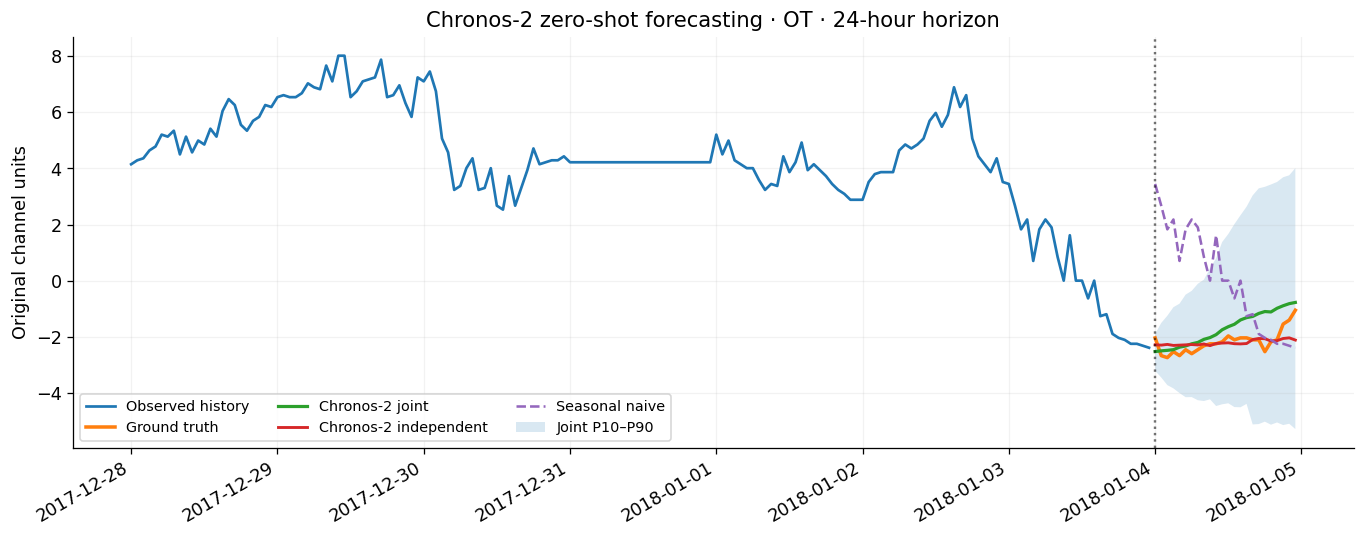

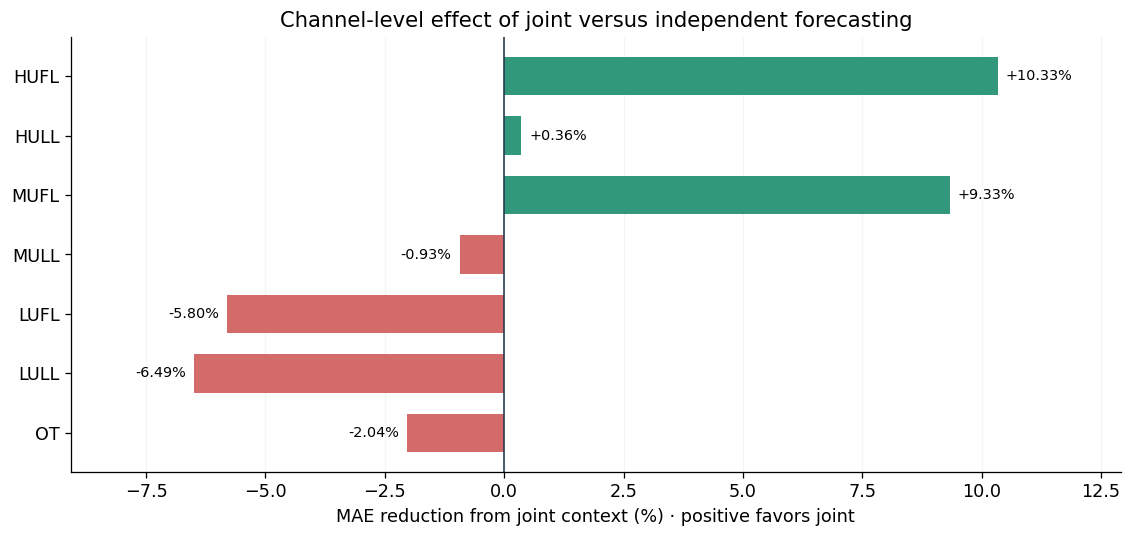

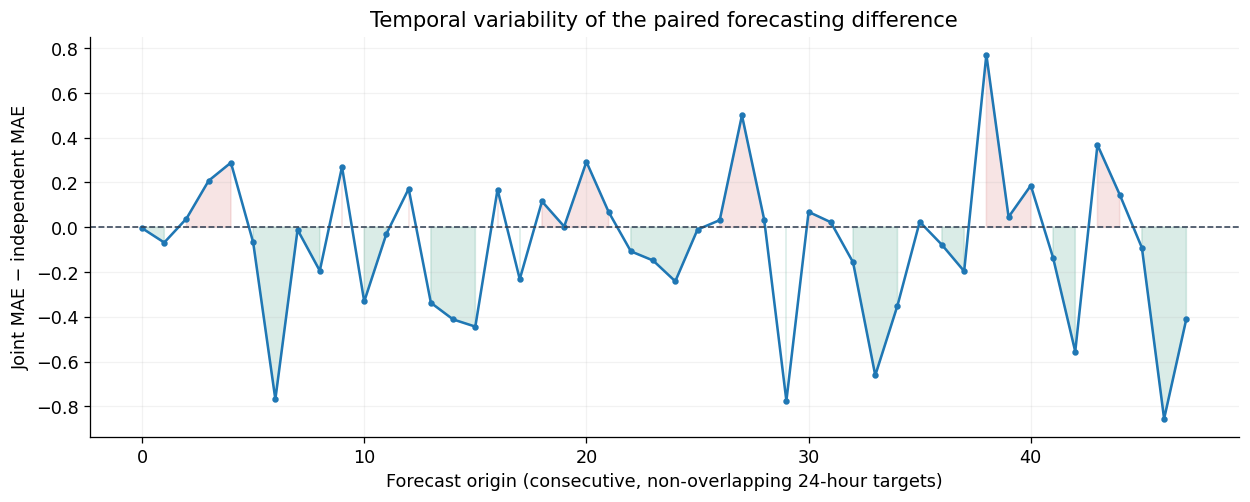

In [8]:
# Figure 1 — Example forecast: first of the 48 primary origins.
i, j = 0, channels.index("OT")
o = int(origins[i])
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(frame.date.iloc[o-CONTEXT:o], contexts[i, j], label="Observed history", lw=1.7)
times = frame.date.iloc[o:o+HORIZON]
ax.plot(times, truth[i, j], label="Ground truth", lw=2.2)
ax.plot(times, forecast_joint[i, j], label="Chronos-2 joint", lw=2)
ax.plot(times, forecast_independent[i, j], label="Chronos-2 independent", lw=1.8)
ax.plot(times, seasonal_naive[i, j], "--", label="Seasonal naive", lw=1.6)
ax.fill_between(times, joint_q[i, j, :, 0], joint_q[i, j, :, 2],
                alpha=0.17, label="Joint P10–P90")
ax.axvline(times.iloc[0], color="black", ls=":", alpha=0.55)
ax.set_title(f"Chronos-2 zero-shot forecasting · {channels[j]} · 24-hour horizon")
ax.set_ylabel("Original channel units")
ax.legend(ncol=3, fontsize=9)
ax.grid(alpha=0.16)
fig.autofmt_xdate(); plt.tight_layout()
fig.savefig(OUT / "forecast_example.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure 2 — Per-channel relative MAE improvement, joint over independent.
change = mae_pair["Joint improvement (%)"]
fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(change.index, change.values,
               color=["#32987c" if x > 0 else "#d36b6b" for x in change], height=.65)
ax.axvline(0, color="#24354b", lw=1)
ax.invert_yaxis(); ax.set_axisbelow(True); ax.grid(axis="x", alpha=.13)
ax.set_xlabel("MAE reduction from joint context (%) · positive favors joint")
ax.set_title("Channel-level effect of joint versus independent forecasting")
margin = max(2.5, float(abs(change).max())*.25)
ax.set_xlim(min(0,change.min())-margin, max(0,change.max())+margin)
for bar, v in zip(bars, change.values):
    ax.annotate(f"{v:+.2f}%", (v, bar.get_y()+bar.get_height()/2),
                xytext=(5 if v>=0 else -5, 0), textcoords="offset points",
                ha="left" if v>=0 else "right", va="center", fontsize=9)
plt.tight_layout(); fig.savefig(OUT / "joint_context_by_channel.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure 3 — Difference by forecast origin; positive favors independent.
fig, ax = plt.subplots(figsize=(11,4.5))
ax.plot(origin_diff.index, origin_diff, marker="o", ms=3, lw=1.6)
ax.axhline(0, ls="--", color="#334155", lw=1)
ax.fill_between(origin_diff.index, origin_diff, 0, where=origin_diff > 0,
                color="#d36b6b", alpha=.18)
ax.fill_between(origin_diff.index, origin_diff, 0, where=origin_diff < 0,
                color="#32987c", alpha=.18)
ax.set_xlabel("Forecast origin (consecutive, non-overlapping 24-hour targets)")
ax.set_ylabel("Joint MAE − independent MAE")
ax.set_title("Temporal variability of the paired forecasting difference")
ax.grid(alpha=.16)
plt.tight_layout(); fig.savefig(OUT / "temporal_paired_mae_difference.png", dpi=200, bbox_inches="tight")
plt.show()

## 7 · Interpretation, Limitations & Reproducibility

### Interpretation

The experimental results evaluate whether Chronos-2 provides competitive zero-shot forecasting performance relative to classical baselines and whether joint-channel inference offers advantages over independent-channel forecasting. Differences are assessed globally, across individual channels, and across forecast origins. Empirical prediction interval coverage is also analyzed to characterize uncertainty estimates. The findings are interpreted within the scope of the evaluated dataset and forecasting protocol.

### Limitations

- **Pretraining exposure:** Potential overlap between ETTh1 and the model's pretraining data cannot be ruled out. Zero-shot refers to inference without task-specific fine-tuning.
- **Evaluation scope:** The experiments use 48 consecutive forecast origins from a single dataset. Temporal dependence and limited dataset diversity constrain generalizability.
- **Model configuration:** Context length, forecast horizon, and inference settings are fixed without hyperparameter optimization.
- **Metric interpretation:** Macro-averaged errors combine channels in their original numerical scales. Results do not establish causal relationships between channels.
- **Computational evaluation:** Runtime measurements are descriptive and do not constitute a controlled inference-latency benchmark.

### Reproducibility

The notebook automatically exports forecasting metrics, channel-level comparisons, empirical prediction interval coverage, experimental figures, and execution metadata. A structured JSON file and a Markdown experiment report are generated from the current evaluation results.

In [9]:

# EXPERIMENT REPORT & REPRODUCIBILITY
def metric_text(table, name, metric):
    return float(table.loc[name, metric])

# 1. Main results
joint_mae = metric_text(macro, "Chronos-2 joint", "MAE")
ind_mae = metric_text(macro, "Chronos-2 independent", "MAE")
joint_rmse = metric_text(macro, "Chronos-2 joint", "RMSE")
ind_rmse = metric_text(macro, "Chronos-2 independent", "RMSE")
seasonal_mae = metric_text(macro, "Seasonal naive", "MAE")
seasonal_rmse = metric_text(macro, "Seasonal naive", "RMSE")
relative_joint_gain = 100 * (ind_mae - joint_mae) / ind_mae
relative_baseline_gain = 100 * (seasonal_mae - joint_mae) / seasonal_mae
better_joint = int((mae_pair["Joint improvement (%)"] > 0).sum())

# 2. Machine-readable experiment metadata
manifest = {"title": "Chronos-2 zero-shot forecasting evaluation",
    "dataset": "ETTh1", "data_source": DATA_URL,
    "test_partition": "Time-Series-Library conventional ETTh1 test split",
    "model": MODEL_ID, "model_package_version": version("chronos-forecasting"),
    "torch_version": torch.__version__, "python_version": platform.python_version(),
    "device": DEVICE, "seed": SEED, "channels": channels, "context_hours": CONTEXT,
    "horizon_hours": HORIZON, "forecast_origins": N_ORIGINS,
    "first_target_timestamp": (frame.date.iloc[origins[0]].isoformat()),
    "last_target_timestamp": (frame.date.iloc[origins[-1] + HORIZON - 1].isoformat()),
    "input_shapes": {"joint": [len(channels), CONTEXT], "independent": [CONTEXT]},
    "fine_tuning": False, "cross_learning_across_tasks": False,
    "macro_metrics": macro.round(6).to_dict(orient="index"),
    "channel_metrics": channel_metrics.to_dict(orient="records"),
    "joint_improvement_percent": round(relative_joint_gain, 4),
    "coverage_nominal": 0.8,
    "empirical_coverage": {configuration: dict(zip(subset["channel"],
                subset["coverage"].astype(float)))
        for configuration, subset in coverage_table.groupby("configuration")},
    "inference_seconds_diagnostic_only": {"joint": round(joint_time, 3),
        "independent": round(independent_time, 3)},
    "limitations": ["Single dataset and contiguous evaluation period",
        "Potential overlap with model pretraining data",
        "No task-specific fine-tuning",
        "No controlled inference latency benchmark",
        "Macro metrics use original channel scales",
        "No statistical significance assessment",
        "No causal identification of cross-channel effects"]}
json_path = OUT / "results.json"
json_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")

# 3. Human-readable technical report
report = f"""# Experiment Report
## Chronos-2: Zero-Shot Forecasting of Multivariate Sensor Data

**Dataset:** ETTh1
**Model:** `{MODEL_ID}`
**Evaluation:** Conventional ETTh1 test partition
**Model adaptation:** None (zero-shot inference)

### 1. Experimental configuration

| Parameter | Value |
|---|---|
| Input channels | {len(channels)} |
| Historical context | {CONTEXT} hours |
| Forecast horizon | {HORIZON} hours |
| Forecast origins | {N_ORIGINS} |
| Target overlap | None |
| Evaluation start | {frame.date.iloc[origins[0]]} |
| Evaluation end | {frame.date.iloc[origins[-1] + HORIZON - 1]} |
| Hardware | {DEVICE.upper()} |
| Model package | chronos-forecasting {version("chronos-forecasting")} |

### 2. Forecasting performance

The evaluation compares persistence, seasonal naive,
and two Chronos-2 inference configurations.

MAE and RMSE are computed separately for each channel
and subsequently macro-averaged across the seven channels.

| Method | Macro MAE ↓ | Macro RMSE ↓ |
|:--|--:|--:|
"""

for name in METHOD_ORDER:
    report += (
        f"| {name} | "
        f"{macro.loc[name, 'MAE']:.3f} | "
        f"{macro.loc[name, 'RMSE']:.3f} |\n"
    )

report += f"""
### 3. Joint versus independent forecasting

Joint-channel inference achieved a macro MAE of
**{joint_mae:.3f}**, compared with **{ind_mae:.3f}**
for independent-channel inference.

This represents a relative MAE reduction of
**{relative_joint_gain:+.2f}%**.

Joint-channel inference achieved lower MAE on
**{better_joint} of {len(channels)} channels**.

Compared with the seasonal naive baseline,
joint-channel Chronos-2 achieved a relative
macro MAE reduction of **{relative_baseline_gain:+.2f}%**.

The results indicate that the effect of cross-channel
context varies across channels and forecast origins.

### 4. Predictive uncertainty

Chronos-2 provides probabilistic forecasts through
estimated quantiles.

The P10-P90 prediction interval was evaluated
against a nominal coverage of 80%.

Empirical coverage is reported separately for each
channel and inference configuration in
`interval_coverage.csv`.

Coverage differences are descriptive and do not
establish calibration on unseen datasets.

### 5. Main findings

**Forecasting performance.**
Chronos-2 achieved competitive zero-shot performance
relative to classical forecasting baselines.

**Multivariate context.**
Joint-channel inference reduced macro-averaged
forecasting error compared with independent inference.
However, the benefit was not uniform across channels.

**Temporal variability.**
Paired forecasting differences varied across temporal
origins, indicating that aggregate performance alone
does not fully characterize the comparison.

**Probabilistic forecasting.**
Prediction quantiles enabled an additional assessment
of empirical interval coverage.

### 6. Limitations

- **Pretraining exposure:** Potential overlap between
  ETTh1 and Chronos-2 pretraining data cannot be
  ruled out.
- **Evaluation scope:** Results are based on 48
  consecutive daily forecast origins from one dataset.
  Temporal dependence may limit generalizability.
- **Model configuration:** Context length, forecast
  horizon and inference settings were fixed without
  hyperparameter optimization.
- **Metric interpretation:** Macro-averaged errors
  combine channels in their original numerical scales.
- **Causal interpretation:** The input ablation does
  not establish causal dependencies between channels.
- **Computational evaluation:** Inference times are
  descriptive rather than controlled latency benchmarks.

### 7. Conclusion

This case study demonstrates a reproducible evaluation
of a pretrained time-series foundation model under
controlled forecasting conditions.

The experiments compare classical forecasting baselines
with independent and joint-channel inference, assess
predictive uncertainty, and examine how performance
varies across channels and temporal origins.

The findings highlight the importance of rigorous
evaluation when adapting foundation models to
multivariate sensor data.

---

**Reproducibility**

All metrics, visualizations and experiment metadata
are generated programmatically from the current run.
"""

# 4. Save and display report
report_path = OUT / "experiment_report.md"
report_path.write_text(report, encoding="utf-8")
display(Markdown(report))
print("\nExperiment outputs saved successfully")
print("Output directory:", OUT.resolve())
print("\nGenerated files:")
for file in sorted(OUT.iterdir()):
    print(" -", file.name)


# Experiment Report
## Chronos-2: Zero-Shot Forecasting of Multivariate Sensor Data

**Dataset:** ETTh1
**Model:** `amazon/chronos-2`
**Evaluation:** Conventional ETTh1 test partition
**Model adaptation:** None (zero-shot inference)

### 1. Experimental configuration

| Parameter | Value |
|---|---|
| Input channels | 7 |
| Historical context | 168 hours |
| Forecast horizon | 24 hours |
| Forecast origins | 48 |
| Target overlap | None |
| Evaluation start | 2018-01-04 00:00:00 |
| Evaluation end | 2018-02-20 23:00:00 |
| Hardware | CPU |
| Model package | chronos-forecasting 2.3.2 |

### 2. Forecasting performance

The evaluation compares persistence, seasonal naive,
and two Chronos-2 inference configurations.

MAE and RMSE are computed separately for each channel
and subsequently macro-averaged across the seven channels.

| Method | Macro MAE ↓ | Macro RMSE ↓ |
|:--|--:|--:|
| Persistence | 1.972 | 3.212 |
| Seasonal naive | 1.313 | 2.115 |
| Chronos-2 joint | 1.275 | 2.108 |
| Chronos-2 independent | 1.356 | 2.257 |

### 3. Joint versus independent forecasting

Joint-channel inference achieved a macro MAE of
**1.275**, compared with **1.356**
for independent-channel inference.

This represents a relative MAE reduction of
**+5.92%**.

Joint-channel inference achieved lower MAE on
**3 of 7 channels**.

Compared with the seasonal naive baseline,
joint-channel Chronos-2 achieved a relative
macro MAE reduction of **+2.87%**.

The results indicate that the effect of cross-channel
context varies across channels and forecast origins.

### 4. Predictive uncertainty

Chronos-2 provides probabilistic forecasts through
estimated quantiles.

The P10-P90 prediction interval was evaluated
against a nominal coverage of 80%.

Empirical coverage is reported separately for each
channel and inference configuration in
`interval_coverage.csv`.

Coverage differences are descriptive and do not
establish calibration on unseen datasets.

### 5. Main findings

**Forecasting performance.**
Chronos-2 achieved competitive zero-shot performance
relative to classical forecasting baselines.

**Multivariate context.**
Joint-channel inference reduced macro-averaged
forecasting error compared with independent inference.
However, the benefit was not uniform across channels.

**Temporal variability.**
Paired forecasting differences varied across temporal
origins, indicating that aggregate performance alone
does not fully characterize the comparison.

**Probabilistic forecasting.**
Prediction quantiles enabled an additional assessment
of empirical interval coverage.

### 6. Limitations

- **Pretraining exposure:** Potential overlap between
  ETTh1 and Chronos-2 pretraining data cannot be
  ruled out.
- **Evaluation scope:** Results are based on 48
  consecutive daily forecast origins from one dataset.
  Temporal dependence may limit generalizability.
- **Model configuration:** Context length, forecast
  horizon and inference settings were fixed without
  hyperparameter optimization.
- **Metric interpretation:** Macro-averaged errors
  combine channels in their original numerical scales.
- **Causal interpretation:** The input ablation does
  not establish causal dependencies between channels.
- **Computational evaluation:** Inference times are
  descriptive rather than controlled latency benchmarks.

### 7. Conclusion

This case study demonstrates a reproducible evaluation
of a pretrained time-series foundation model under
controlled forecasting conditions.

The experiments compare classical forecasting baselines
with independent and joint-channel inference, assess
predictive uncertainty, and examine how performance
varies across channels and temporal origins.

The findings highlight the importance of rigorous
evaluation when adapting foundation models to
multivariate sensor data.

---

**Reproducibility**

All metrics, visualizations and experiment metadata
are generated programmatically from the current run.



Experiment outputs saved successfully
Output directory: C:\Users\Estela Sánchez\OneDrive - Universidad Rey Juan Carlos\Escritorio\Trabajo\Time-Series Foundation Models\chronos2_results_final

Generated files:
 - channel_metrics_48.csv
 - experiment_report.md
 - forecast_example.png
 - interval_coverage.csv
 - joint_context_by_channel.png
 - joint_vs_independent_mae.csv
 - macro_metrics_48.csv
 - paired_origin_channel_metrics.csv
 - results.json
 - temporal_paired_mae_difference.png


---
### Reproducibility and source notes

- Chronos-2 model and API: [Amazon Chronos forecasting repository](https://github.com/amazon-science/chronos-forecasting) (refer to the `Chronos2Pipeline` docs for 1-D versus 2-D inputs and `cross_learning`).
- ETTh1 source: [thuml / Time-Series-Library](https://huggingface.co/datasets/thuml/Time-Series-Library); conventional test boundaries: [Dataset_ETT_hour loader](https://github.com/thuml/Time-Series-Library/blob/main/data_provider/data_loader.py).
- Baselines are deliberately simple. Additional datasets, train/test comparisons under known pretraining constraints, and calibration analyses would be required for a production or publication-grade claim.